In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
#load all score data sets ["Neighborhood", "Metric Name"]
crime_scores = pd.read_csv("data/crime_scores.csv")
#housing_scores = pd.read_csv("")
#transit_scores = pd.read_csv("")
#school_scores = pd.read_csv("")

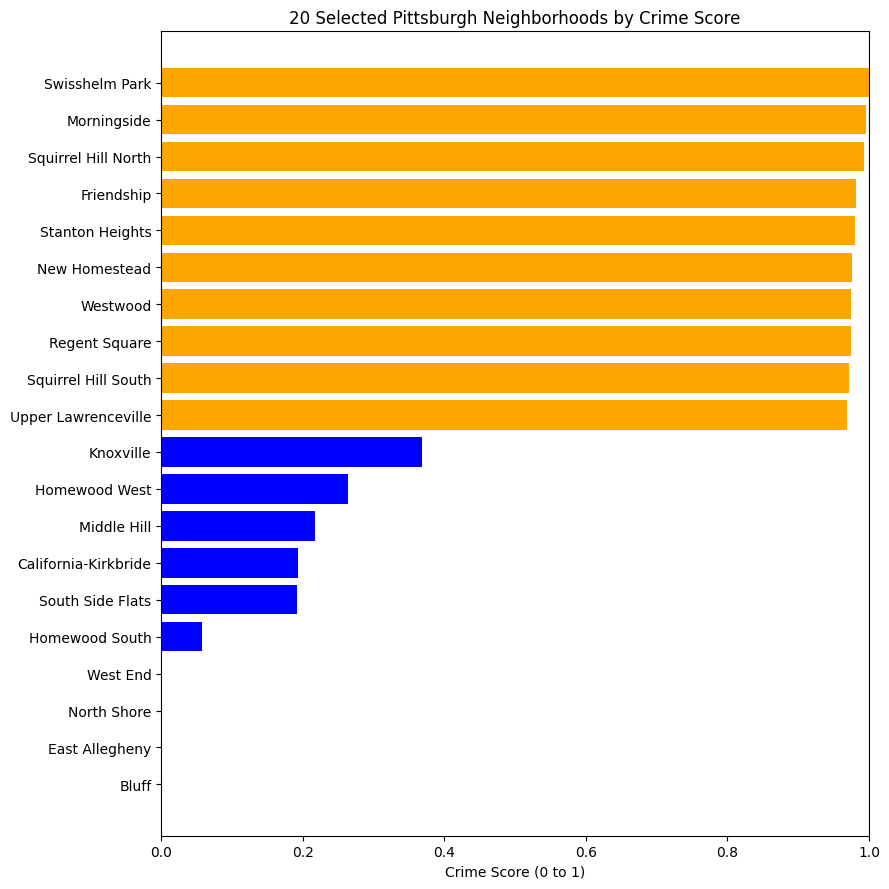

In [8]:
#analyzing the crime score data (Author: Cooper)
sorted = crime_scores.sort_values(by = "Crime Score")
bottom10 = sorted.head(10)
top10 = sorted.tail(10)
together = pd.concat([bottom10, top10])

colors = ["orange" if neighborhood in top10.index else "blue" for neighborhood in together.index]

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(together["Neighborhood"], together["Crime Score"], color=colors)
ax.set_title("20 Selected Pittsburgh Neighborhoods by Crime Score")
ax.set_xlabel("Crime Score (0 to 1)")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

In [20]:
print("Great Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.8, 1.0)].shape[0]))
print("Good Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.6, 0.8)].shape[0]))
print("Decent Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.4, 0.6)].shape[0]))
print("Fine Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.2, 0.4)].shape[0]))
print("Bad Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.0, 0.2)].shape[0]))

Great Neighborhoods: 46
Good Neighborhoods: 17
Decent Neighborhoods: 9
Fine Neighborhoods: 4
Bad Neighborhoods: 7


Pittsburgh has many neighborhoods with low crime rates, but a few neighborhoods with very high crime rates. An effective final metric should rank the bottom seven to eleven neighborhoods lower than the other 72.

In [ ]:
#merge all score sets and trim into final df
merged_df = crime_scores.merge(housing_scores, on = "Neighborhood", how = "inner").merge(transit_scores, on = "Neighborhood", how = "inner").merge(school_scores, on = "Neighborhood", how = "inner")
print(merged_df.shape)
merged_df["Combined Score"] = (merged_df["Crime Score"] + merged_df[""] + merged_df[""] + merged_df[""]) / 4
final_scores = merged_df[["Neighborhood", "Combined Score"]]
final_scores

In [ ]:
#Plot 10 best neighborhoods and 10 worst neighborhoods (Authors: Cooper, )

sorted = final_scores.sort_values(by = "Combined Score")
bottom10 = sorted.head(10)
top10 = sorted.tail(10)
together = pd.concat([bottom10, top10])

colors = ["orange" if neighborhood in top10.index else "blue" for neighborhood in together.index]

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(together["Neighborhood"], together["Combined Score"], color=colors)
ax.set_title("20 Selected Pittsburgh Neighborhoods by Combined Score")
ax.set_xlabel("Combined Score (0 to 1)")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()


This is where we will analyze the final scores!